In [22]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv('pakistani_ecommerce_dataset.csv')

df.head()

,user_id,gender,age_group,city,product_category,payment_method,order_value,order_status
0,U001,Male,25-34,Islamabad,Home Decor,JazzCash,1899.62,Pending
1,U002,Female,25-34,Lahore,Electronics,EasyPaisa,1592.21,Cancelled
2,U003,Female,25-34,Lahore,Books,Debit Card,3851.78,Cancelled
3,U004,Female,18-24,Lahore,Home Decor,Cash on Delivery,1774.12,Pending
4,U005,Female,35-44,Lahore,Home Decor,EasyPaisa,3611.28,Cancelled


In [23]:
print(df.info())


print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           100 non-null    str    
 1   gender            100 non-null    str    
 2   age_group         100 non-null    str    
 3   city              100 non-null    str    
 4   product_category  100 non-null    str    
 5   payment_method    100 non-null    str    
 6   order_value       100 non-null    float64
 7   order_status      100 non-null    str    
dtypes: float64(1), str(7)
memory usage: 11.3 KB
None
user_id             0
gender              0
age_group           0
city                0
product_category    0
payment_method      0
order_value         0
order_status        0
dtype: int64


In [24]:
category_counts = df['product_category'].value_counts()
print(category_counts)

product_category
Home Decor     30
Clothing       22
Beauty         19
Electronics    18
Books          11
Name: count, dtype: int64


In [25]:
print(df['order_value'].describe())

mean_val = df['order_value'].mean()
median_val = df['order_value'].median()
print(f'Mean Order Value: {mean_val:.2f}')
print(f'Median Order Value: {median_val:.2f}')

count     100.000000
mean     2832.148100
std      1294.037911
min       558.000000
25%      1712.045000
50%      2888.275000
75%      3926.887500
max      4960.980000
Name: order_value, dtype: float64
Mean Order Value: 2832.15
Median Order Value: 2888.28


In [26]:
city_analysis = df.groupby('city')['order_value'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)
print(city_analysis)

            count         mean    median      min      max
city                                                      
Faisalabad     17  2937.084118  3124.820   687.28  4752.53
Islamabad      21  3011.951429  2914.240  1345.65  4960.98
Karachi        24  2956.497917  2947.920   803.40  4903.20
Lahore         18  2785.330000  2776.615   769.62  4912.57
Rawalpindi     20  2447.075500  2491.080   558.00  4785.78


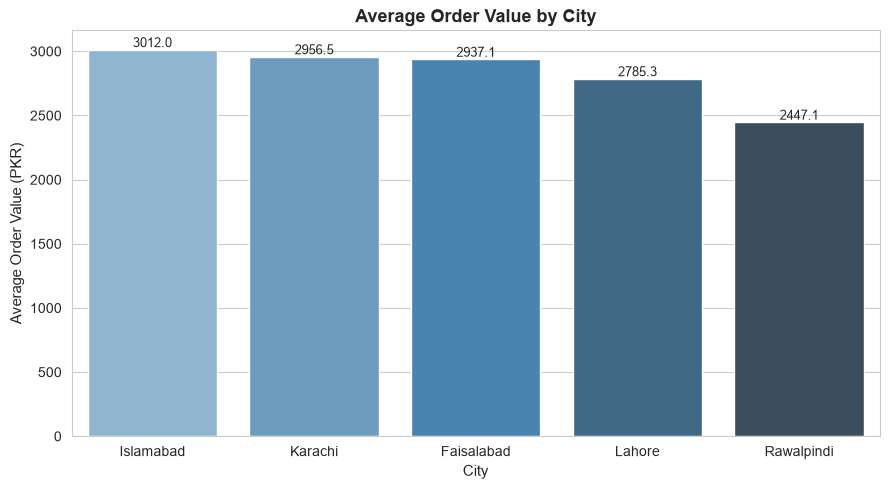

In [27]:
sns.set_style('whitegrid')

plt.figure(figsize=(9, 5))
city_avg = (
    df.groupby('city')['order_value'].mean().sort_values(ascending=False)
)

ax = sns.barplot(
    x=city_avg.index,
    y=city_avg.values,
    palette='Blues_d',
    hue=city_avg.index,
    legend=False,
)
plt.title('Average Order Value by City', fontsize=13, fontweight='bold')
plt.xlabel('City', fontsize=11)
plt.ylabel('Average Order Value (PKR)', fontsize=11)

for p in ax.patches:
  ax.annotate(
      f'{p.get_height():.1f}',
      (p.get_x() + p.get_width() / 2., p.get_height()),
      ha='center',
      va='bottom',
      fontsize=9,
  )

plt.tight_layout()
plt.show()